In [1]:
import tumult as tm
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

%config InlineBackend.figure_format='svg'
plt.style.use('default')
plt.style.use('tumult/Bergemann2020.mplstyle')

In [2]:
from tumult.auxfuncs import marcs_name_to_params, mafags_name_to_params

marcs_grid = Path('/Users/hoppe/Documents/MARCS')
marcs_models = {marcs_name_to_params(m.name):m for m in marcs_grid.glob('*a+0.*.mod')}

#mafags_grid = Path('/mnt/beegfs/gemini/groups/bergemann/users/shared-storage/bergemann-data/atmos/mafags-os/')
#mafags_models = {mafags_name_to_params(m.name):m for m in mafags_grid.glob('*.dat')}

#absmet_files = {0:'input_multi3d/absmet_files/absmet',
#                -1:'input_multi3d/absmet_files/m-1.00a+0.40c+0.00n+0.00o+0.40r+0.00s+0.00v+1.00.bin',
#                -2:'input_multi3d/absmet_files/m-2.00a+0.40c+0.00n+0.00o+0.40r+0.00s+0.00v+1.00.bin',
#                -3:'input_multi3d/absmet_files/m-3.00a+0.40c+0.00n+0.00o+0.40r+0.00s+0.00v+1.00.bin',
#                }

In [ ]:
top = 'CodeRelease/debug'
atom_file = 'input/atoms/atom.mg86g'
atmos_file = '/Users/hoppe/Documents/MARCS/p6500_g+4.0_m0.0_t01_st_z-2.00_a+0.40_c+0.00_n+0.00_o+0.40_r+0.00_s+0.00.mod'
lines = [4571.096, 4702.990, 5183.604, 5528.410, 5711.088]
star = (6500, 4.0, -2.0, 1)

settings = {'atom_params':{'qnorm':1, 'ch0_hmip':False}}
corr, runs = tm.get_NLTE_correction(top, star, atom_file, atmos_file, lines, settings=settings, launch_kwargs={'overwrite':True, 'verbose':False})
[print(f'{l0:.3f} Å: NLTE correction = {corr[l0]:+.2f} dex') for l0 in lines];

No absmet file for [Fe/H]=-2.0!


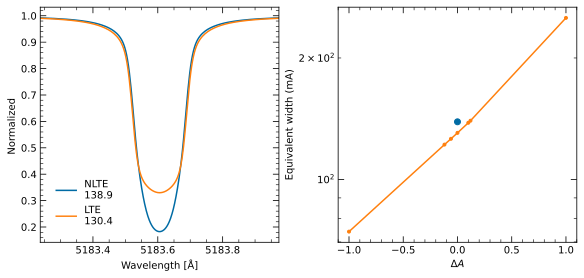

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(8, 3.75), layout='constrained')
kw = {'x0':5183.604, 'dx':0.5}
grid = runs

plt.sca(axs[0])
grid[0.0].crop(**kw).plot(label='NLTE\n{weq:.1f}')
grid[0.0].crop(**kw, LTE=True).plot(label='LTE\n{weq:.1f}')
plt.legend()

plt.sca(axs[1])
das = sorted(grid.keys())
ref = grid[0.0].crop(**kw, LTE=False).get_weq(profile='trapz', auto_crop_core=False).value
weqs = [grid[k].crop(**kw, LTE=True).get_weq(profile='trapz', auto_crop_core=False).value for k in das]
plt.plot(0, ref, marker='o')
plt.plot(das, np.array(weqs), marker='.')
plt.xlabel(r'$\Delta A$')
plt.ylabel('Equivalent width (mA)')
plt.yscale('log')

In [ ]:
top = 'CodeRelease/debug2'
atom_file = 'input/atoms/atom.mg86g'
atmos_file = '/Users/hoppe/Documents/MARCS/p6500_g+4.0_m0.0_t01_st_z-2.00_a+0.40_c+0.00_n+0.00_o+0.40_r+0.00_s+0.00.mod'
lines = [4571.096, 4702.990, 5183.604, 5528.410, 5711.088]
star = (6500, 4.0, -2.0, 1)

settings = {'atom_params':{'qnorm':1, 'ch0_hmip':False}}
corr, runs = tm.get_NLTE_correction(top, star, atom_file, atmos_file, lines, settings=settings, launch_kwargs={'overwrite':True, 'verbose':False})
[print(f'{l0:.3f} Å: NLTE correction = {corr[l0]:+.2f} dex') for l0 in lines];

No absmet file for [Fe/H]=-2.0!
4571.096 Å: NLTE correction = +0.09 dex
4702.990 Å: NLTE correction = +0.12 dex
5183.604 Å: NLTE correction = -0.11 dex
5528.410 Å: NLTE correction = +0.10 dex
5711.088 Å: NLTE correction = +0.10 dex


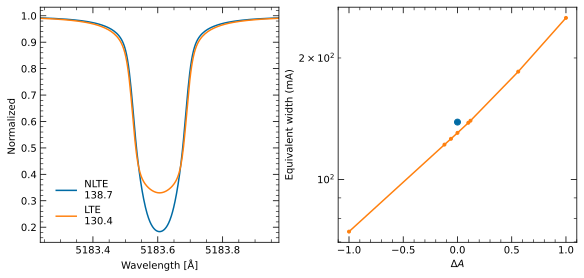

In [3]:
fig, axs = plt.subplots(1, 2, figsize=(8, 3.75), layout='constrained')
kw = {'x0':5183.604, 'dx':0.5}
grid = runs

plt.sca(axs[0])
grid[0.0].crop(**kw).plot(label='NLTE\n{weq:.1f}')
grid[0.0].crop(**kw, LTE=True).plot(label='LTE\n{weq:.1f}')
plt.legend()

plt.sca(axs[1])
das = sorted(grid.keys())
ref = grid[0.0].crop(**kw, LTE=False).get_weq(profile='trapz', auto_crop_core=False).value
weqs = [grid[k].crop(**kw, LTE=True).get_weq(profile='trapz', auto_crop_core=False).value for k in das]
plt.plot(0, ref, marker='o')
plt.plot(das, np.array(weqs), marker='.')
plt.xlabel(r'$\Delta A$')
plt.ylabel('Equivalent width (mA)')
plt.yscale('log')

In [5]:
top = 'CodeRelease/debug'
atom_file = 'input/atoms/atom.mg86g'
atmos_file = '/Users/hoppe/Documents/MARCS/p6500_g+4.0_m0.0_t01_st_z-2.00_a+0.40_c+0.00_n+0.00_o+0.40_r+0.00_s+0.00.mod'
lines = [4571.096, 4702.990, 5183.604, 5528.410, 5711.088]
star = (6500, 4.0, -2.0, 1)

settings = {'atom_params':{'qnorm':1, 'ch0_hmip':False}}
corr, runs = tm.get_NLTE_correction(top, star, atom_file, atmos_file, lines, settings=settings, launch_kwargs={'overwrite':True, 'verbose':False})
[print(f'{l0:.3f} Å: NLTE correction = {corr[l0]:+.2f} dex') for l0 in lines];

No absmet file for [Fe/H]=-2.0!
4571.096 Å: NLTE correction = +0.09 dex
4702.990 Å: NLTE correction = +0.12 dex
5183.604 Å: NLTE correction = -0.11 dex
5528.410 Å: NLTE correction = +0.10 dex
5711.088 Å: NLTE correction = +0.10 dex


In [7]:
top = 'CodeRelease/debug'
atom_file = 'input/atoms/atom.mg86g'
atmos_file = '/Users/hoppe/Documents/MARCS/p6500_g+4.0_m0.0_t01_st_z-2.00_a+0.40_c+0.00_n+0.00_o+0.40_r+0.00_s+0.00.mod'
lines = [4571.096, 4702.990, 5172.684, 5183.604, 5528.410, 5711.088]
star = (6500, 4.0, -2.0, 1)

settings = {'atom_params':{'qnorm':1, 'ch0_hmip':False}}
corr, runs = tm.get_NLTE_correction(top, star, atom_file, atmos_file, lines, ref='NLTE', settings=settings, launch_kwargs={'overwrite':True, 'verbose':False})
[print(f'{l0:.3f} Å: NLTE correction = {corr[l0]:+.2f} dex') for l0 in lines];

No absmet file for [Fe/H]=-2.0!
4571.096 Å: NLTE correction = +0.09 dex
4702.990 Å: NLTE correction = +0.12 dex
5172.684 Å: NLTE correction = -0.10 dex
5183.604 Å: NLTE correction = -0.11 dex
5528.410 Å: NLTE correction = +0.10 dex
5711.088 Å: NLTE correction = +0.10 dex


In [9]:
top = 'CodeRelease/debug'
atom_file = 'input/atoms/atom.mg86g'
atmos_file = '/Users/hoppe/Documents/MARCS/p6500_g+4.0_m0.0_t01_st_z-2.00_a+0.40_c+0.00_n+0.00_o+0.40_r+0.00_s+0.00.mod'
lines = [4571.096, 4702.990, 5172.684, 5183.604, 5528.410, 5711.088]
star = (6500, 4.0, -2.0, 1)

settings = {'atom_params':{'qnorm':1, 'ch0_hmip':False},
            'composition_params':{'m1d_legacy_mode':True}}
corr, runs = tm.get_NLTE_correction(top, star, atom_file, atmos_file, lines, ref='NLTE', settings=settings, launch_kwargs={'overwrite':True, 'verbose':False})
[print(f'{l0:.3f} Å: NLTE correction = {corr[l0]:+.2f} dex') for l0 in lines];

No absmet file for [Fe/H]=-2.0!
4571.096 Å: NLTE correction = +0.12 dex
4702.990 Å: NLTE correction = +0.14 dex
5172.684 Å: NLTE correction = -0.04 dex
5183.604 Å: NLTE correction = -0.06 dex
5528.410 Å: NLTE correction = +0.14 dex
5711.088 Å: NLTE correction = +0.13 dex


In [10]:
top = 'CodeRelease/debug'
atom_file = 'input/atoms/atom.mg86g'
atmos_file = '/Users/hoppe/Documents/MARCS/p6500_g+4.0_m0.0_t01_st_z-2.00_a+0.40_c+0.00_n+0.00_o+0.40_r+0.00_s+0.00.mod'
lines = [4571.096, 4702.990, 5172.684, 5183.604, 5528.410, 5711.088]
star = (6000, 4.0, -2.0, 1)

settings = {'atom_params':{'qnorm':1, 'ch0_hmip':False},
            'composition_params':{'m1d_legacy_mode':True}}
corr, runs = tm.get_NLTE_correction(top, star, atom_file, atmos_file, lines, ref='NLTE', settings=settings, launch_kwargs={'overwrite':True, 'verbose':False})
[print(f'{l0:.3f} Å: NLTE correction = {corr[l0]:+.2f} dex') for l0 in lines];

No absmet file for [Fe/H]=-2.0!
4571.096 Å: NLTE correction = +0.12 dex
4702.990 Å: NLTE correction = +0.14 dex
5172.684 Å: NLTE correction = -0.04 dex
5183.604 Å: NLTE correction = -0.06 dex
5528.410 Å: NLTE correction = +0.14 dex
5711.088 Å: NLTE correction = +0.13 dex


In [4]:
top = 'CodeRelease/debug'
atom_file = 'input/atoms/atom.mg86g'
atmos_file = '/Users/hoppe/Documents/MARCS/p6500_g+4.0_m0.0_t01_st_z-2.00_a+0.40_c+0.00_n+0.00_o+0.40_r+0.00_s+0.00.mod'
lines = [4571.096, 4702.990, 5183.604, 5528.410, 5711.088]
star = (6500, 4.0, -2.0, 1)

settings = {'atom_params':{'qnorm':10, 'ch0_hmip':False}}
corr, runs = tm.get_NLTE_correction(top, star, atom_file, atmos_file, lines, settings=settings, launch_kwargs={'overwrite':True, 'verbose':False})
[print(f'{l0:.3f} Å: NLTE correction = {corr[l0]:+.2f} dex') for l0 in lines];

No absmet file for [Fe/H]=-2.0!
4571.096 Å: NLTE correction = +0.09 dex
4702.990 Å: NLTE correction = +0.14 dex
5183.604 Å: NLTE correction = -0.08 dex
5528.410 Å: NLTE correction = +0.12 dex
5711.088 Å: NLTE correction = +0.10 dex


In [3]:
top = 'CodeRelease/debug'
atom_file = 'input/atoms/atom.mg86g'
atmos_file = '/Users/hoppe/Documents/MARCS/p6500_g+4.0_m0.0_t01_st_z-2.00_a+0.40_c+0.00_n+0.00_o+0.40_r+0.00_s+0.00.mod'
lines = [4571.096, 4702.990, 5183.604, 5528.410, 5711.088]
star = (6500, 4.0, -2.0, 1)

settings = {'atom_params':{'qnorm':10, 'ch0_hmip':True}}
corr, runs = tm.get_NLTE_correction(top, star, atom_file, atmos_file, lines, settings=settings, launch_kwargs={'overwrite':True, 'verbose':False})
[print(f'{l0:.3f} Å: NLTE correction = {corr[l0]:+.2f} dex') for l0 in lines];

No absmet file for [Fe/H]=-2.0!
4571.096 Å: NLTE correction = +0.12 dex
4702.990 Å: NLTE correction = +0.20 dex
5183.604 Å: NLTE correction = -0.06 dex
5528.410 Å: NLTE correction = +0.17 dex
5711.088 Å: NLTE correction = +0.13 dex


In [11]:
top = 'CodeRelease/debug'
atom_file = 'input/atoms/atom.mg86g'
atmos_file = '/Users/hoppe/Documents/MARCS/p6500_g+4.0_m0.0_t01_st_z-2.00_a+0.40_c+0.00_n+0.00_o+0.40_r+0.00_s+0.00.mod'
lines = [4571.096, 4702.990, 5183.604, 5528.410, 5711.088]
star = (6500, 4.0, -2.0, 1)

settings = {'atom_params':{'qnorm':10, 'ch0_hmip':True}}
corr, runs = tm.get_NLTE_correction(top, star, atom_file, atmos_file, lines, settings=settings, launch_kwargs={'overwrite':True, 'verbose':False})
[print(f'{l0:.3f} Å: NLTE correction = {corr[l0]:+.2f} dex') for l0 in lines];

No absmet file for [Fe/H]=-2.0!
4571.096 Å: NLTE correction = +0.12 dex
4702.990 Å: NLTE correction = +0.20 dex
5183.604 Å: NLTE correction = -0.06 dex
5528.410 Å: NLTE correction = +0.17 dex
5711.088 Å: NLTE correction = +0.13 dex


In [3]:
top = 'CodeRelease/debug'
atom_file = Path('input/atoms/atom.mg86g')
lines = [4571.096, 4702.990, 5183.604, 5528.410, 5711.088]

stars = [
  # Teff, logg, [Fe/H], vmic
  (6500, 4.0, -2.0, 1),
  ]

settings = {'atom_params':{'qnorm':10, 'ch0_hmip':True}}

df, runs = tm.get_NLTE_corrections(top, stars, atom_file, marcs_models, lines, settings=settings, launch_kwargs={'overwrite':True, 'verbose':False})

No absmet file for [Fe/H]=-2.0!
   Teff logg [Fe/H] vmic  4571.096  4702.99  5183.604  5528.41  5711.088
0  6500 4.00  -2.00    1      0.12     0.20     -0.06     0.17      0.13


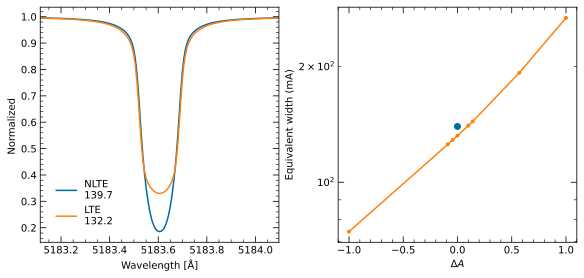

In [41]:
fig, axs = plt.subplots(1, 2, figsize=(8, 3.75), layout='constrained')
kw = {'x0':5183.604, 'dx':0.5}
grid = runs[stars[0]]

plt.sca(axs[0])
grid[0.0].crop(**kw).plot(label='NLTE\n{weq:.1f}')
grid[0.0].crop(**kw, LTE=True).plot(label='LTE\n{weq:.1f}')
plt.legend()

plt.sca(axs[1])
das = sorted(grid.keys())
ref = grid[0.0].crop(**kw, LTE=False).get_weq(profile='trapz', auto_crop_core=False).value
weqs = [grid[k].crop(**kw, LTE=True).get_weq(profile='trapz', auto_crop_core=False).value for k in das]
plt.plot(0, ref, marker='o')
plt.plot(das, np.array(weqs), marker='.')
plt.xlabel(r'$\Delta A$')
plt.ylabel('Equivalent width (mA)')
plt.yscale('log')

In [5]:
top = 'CodeRelease/debug'
atom_file = Path('input/atoms/atom.mg86f')
lines = [4571.096, 4702.990, 5183.604, 5528.410, 5711.088]

stars = [
  # Teff, logg, [Fe/H], vmic
  (6500, 4.0, -2.0, 1),
  ]

settings = {'atom_params':{'ch0_hmip':True}}

df, runs = tm.get_NLTE_corrections(top, stars, atom_file, lines, marcs_models, settings=settings, launch_kwargs={'overwrite':True, 'verbose':False})

No absmet file for [Fe/H]=-2.0!
   Teff logg [Fe/H] vmic  4571.096  4702.99  5183.604  5528.41  5711.088
0  6500 4.00  -2.00    1      0.08     0.10     -0.26     0.11      0.08


In [11]:
top = 'CodeRelease/debug'
atom_file = Path('input/atoms/atom.mg86f')
lines = [4571.096, 4702.990, 5183.604, 5528.410, 5711.088]

stars = [
  # Teff, logg, [Fe/H], vmic
  (6500, 4.0, -2.0, 1),
  ]

settings = {'atom_params':{'qnorm':1}}

df, runs = tm.get_NLTE_corrections(top, stars, atom_file, lines, marcs_models, settings=settings, launch_kwargs={'overwrite':True, 'verbose':False})

No absmet file for [Fe/H]=-2.0!
   Teff logg [Fe/H] vmic  4571.096  4702.99  5183.604  5528.41  5711.088
0  6500 4.00  -2.00    1      0.04     0.07     -0.71     0.07      0.06


In [10]:
top = 'CodeRelease/debug'
atom_file = Path('input/atoms/atom.mg86f')
lines = [4571.096, 4702.990, 5183.604, 5528.410, 5711.088]

stars = [
  # Teff, logg, [Fe/H], vmic
  (6500, 4.0, -2.0, 1),
  ]

settings = {'atom_params':{'qnorm':1, 'nq_min':51}}

df, runs = tm.get_NLTE_corrections(top, stars, atom_file, lines, marcs_models, settings=settings, launch_kwargs={'overwrite':True, 'verbose':False})

No absmet file for [Fe/H]=-2.0!


In [12]:
top = 'CodeRelease/debug'
atom_file = Path('input/atoms/atom.mg86f')
lines = [4571.096, 4702.990, 5183.604, 5528.410, 5711.088]

stars = [
  # Teff, logg, [Fe/H], vmic
  (6500, 4.0, -2.0, 1),
  ]

settings = {'atom_params':{'qnorm':10, 'nq_min':51}}

df, runs = tm.get_NLTE_corrections(top, stars, atom_file, lines, marcs_models, settings=settings, launch_kwargs={'overwrite':True, 'verbose':False})

No absmet file for [Fe/H]=-2.0!
   Teff logg [Fe/H] vmic  4571.096  4702.99  5183.604  5528.41  5711.088
0  6500 4.00  -2.00    1      0.05     0.06     -0.14     0.07      0.06


In [19]:
top = 'CodeRelease/debug'
star = (6400, 4.0, -2.0, 1)
settings = {'atom_params':{'atom_file':'input/atoms/atom.mg86f'}}
default = 'demo.nml'

grid = tm.build_stellar_grid(top, star, marcs_models, settings=settings, launch_kwargs={'overwrite':True, 'verbose':True, 'default':default})

CodeRelease/debug/t65g40m-20v1.nml launchingCodeRelease/debug/t62g40m-20v1.nml launching

